# 07_01 Bayesian Updating and Conjugate Families

**Learning objectives**
- State **Bayes' theorem for parameters**: posterior $\propto$ likelihood $\times$ prior, and explain what each part means.
- Derive and use the three classic **conjugate pairs**: Beta-Binomial, Gamma-Poisson and Normal-Normal.
- See the posterior mean as a **weighted average** of the prior mean and the data, and watch it **shrink** towards the data as the sample grows.
- Check a Bayesian computation by **simulation** and by **sequential updating**.

**Prerequisites:** [00_05 Bayes' theorem](../../module_00_foundations/notebooks/00_05_bayes_theorem.ipynb), [02_03 Exponential, Gamma and Erlang](../../module_02_continuous/notebooks/02_03_exponential_gamma_erlang.ipynb), [02_04 Beta](../../module_02_continuous/notebooks/02_04_beta.ipynb), [06_01 Estimation](../../module_06_inference/notebooks/06_01_estimation_mle_mom.ipynb) (likelihood).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Bayes' theorem** for events: $P(A\mid B)=P(B\mid A)P(A)/P(B)$ (00_05).
- The **likelihood** $L(\theta)=P(\text{data}\mid\theta)$ as a function of the parameter (06_01); its maximum is the MLE.
- The **Beta**$(a,b)$ density $\propto\theta^{a-1}(1-\theta)^{b-1}$ on $(0,1)$ with mean $a/(a+b)$; the **Gamma**$(\alpha,\beta)$ density $\propto\lambda^{\alpha-1}e^{-\beta\lambda}$ with mean $\alpha/\beta$ (rate parametrisation).

## 3. Intuition and story

A frequentist treats the parameter as a fixed unknown number and the data as random. A **Bayesian** treats the parameter as *uncertain*, describes that uncertainty with a probability distribution, and **updates** it when data arrive. We start with a **prior** (what we believed before the data), multiply by the **likelihood** (how well each parameter value explains the data), and normalise to get the **posterior** (what we believe now). Yesterday's posterior is tomorrow's prior, so learning is just repeated multiplication.

Take a new online ad. Past ads in this category had click rates around 10 %, and we hold that belief with the strength of about 20 impressions. After 200 impressions with 30 clicks (15 %) our belief moves from 10 % towards 15 %, but not all the way, because the prior still carries some weight. With 20,000 impressions the prior would be forgotten.

## 4. Formal definitions

**Bayes' theorem for a parameter** $\theta$ with data $x$:
$$p(\theta\mid x)=\frac{p(x\mid\theta)\,p(\theta)}{p(x)}\ \propto\ \underbrace{p(x\mid\theta)}_{\text{likelihood}}\ \underbrace{p(\theta)}_{\text{prior}},\qquad p(x)=\int p(x\mid\theta)p(\theta)\,d\theta\ \text{(evidence)}.$$

A prior family is **conjugate** to a likelihood if the posterior is in the same family, only with updated parameters.

| Likelihood | Prior | Posterior | Reading |
|---|---|---|---|
| $X\sim\mathrm{Binomial}(n,\theta)$ | $\theta\sim\mathrm{Beta}(a,b)$ | $\mathrm{Beta}(a+x,\;b+n-x)$ | $a$ prior successes, $b$ prior failures |
| $X_i\sim\mathrm{Poisson}(\lambda T_i)$ | $\lambda\sim\mathrm{Gamma}(\alpha,\beta)$ | $\mathrm{Gamma}(\alpha+\sum x_i,\;\beta+\sum T_i)$ | $\alpha$ prior events in $\beta$ prior exposure |
| $X_i\sim N(\mu,\sigma^2)$, $\sigma$ known | $\mu\sim N(\mu_0,\tau_0^2)$ | $N(\mu_n,\tau_n^2)$, see below | precisions add |

For the Normal pair, with **precision** $=1/\text{variance}$: $\ \dfrac1{\tau_n^2}=\dfrac1{\tau_0^2}+\dfrac n{\sigma^2}$ and $\mu_n=\tau_n^2\Big(\dfrac{\mu_0}{\tau_0^2}+\dfrac{n\bar x}{\sigma^2}\Big)$.

## 5. Derivations

### 5.1 Beta-Binomial
Likelihood $\propto\theta^x(1-\theta)^{n-x}$, prior $\propto\theta^{a-1}(1-\theta)^{b-1}$. The product is $\theta^{a+x-1}(1-\theta)^{b+n-x-1}$, the kernel of Beta$(a+x,\,b+n-x)$. **In plain words.** Add the observed successes to $a$ and the failures to $b$; nothing else is needed.

**Posterior mean as a weighted average.** $E[\theta\mid x]=\dfrac{a+x}{a+b+n}=\dfrac{a+b}{a+b+n}\cdot\dfrac a{a+b}+\dfrac n{a+b+n}\cdot\dfrac xn$. **In plain words.** The estimate is a mix of the prior mean and the sample proportion, with weights proportional to the *prior sample size* $a+b$ and the *real sample size* $n$.

### 5.2 Gamma-Poisson
Likelihood $\propto\lambda^{\sum x_i}e^{-\lambda\sum T_i}$, prior $\propto\lambda^{\alpha-1}e^{-\beta\lambda}$; the product is $\lambda^{\alpha+\sum x_i-1}e^{-(\beta+\sum T_i)\lambda}$, i.e. Gamma$(\alpha+\sum x_i,\ \beta+\sum T_i)$. **In plain words.** Add the observed events to $\alpha$ and the observed exposure to $\beta$.

### 5.3 Normal-Normal
Write the log-posterior up to constants: $-\frac{(\mu-\mu_0)^2}{2\tau_0^2}-\frac{\sum(x_i-\mu)^2}{2\sigma^2}$. Collecting the terms in $\mu$: $-\frac12\mu^2\big(\frac1{\tau_0^2}+\frac n{\sigma^2}\big)+\mu\big(\frac{\mu_0}{\tau_0^2}+\frac{n\bar x}{\sigma^2}\big)$, a Normal with precision $\frac1{\tau_0^2}+\frac n{\sigma^2}$ and the mean given above. **In plain words.** Precisions (information) add, and the mean is the precision-weighted average of the prior mean and the sample mean.

### 5.4 Sequential updating equals batch updating
Updating with $x_1$ and then with $x_2$ gives $p(\theta\mid x_1,x_2)\propto p(x_2\mid\theta)\,p(x_1\mid\theta)p(\theta)$, the same as one update with both. **In plain words.** The order and the batching of the data do not matter.

### 5.5 The data eventually overwhelm the prior
As $n\to\infty$ the weight $\frac{n}{a+b+n}\to1$, so the posterior mean tends to $x/n$ and the posterior variance $\frac{(a+x)(b+n-x)}{(a+b+n)^2(a+b+n+1)}\to0$. **In plain words.** Two people with different priors who see the same large data set end up agreeing.

## 6. Properties and relationships

- **MAP and MLE.** The posterior mode (MAP) maximises $\log p(x\mid\theta)+\log p(\theta)$: MLE plus a penalty. A Gaussian prior on weights is **L2 regularisation** (ridge), a Laplace prior is L1 (lasso).
- **Flat and weak priors.** Beta(1,1) is uniform; Beta(0.5,0.5) is Jeffreys' prior; with them the posterior mean is nearly $x/n$.
- **Shrinkage.** The posterior mean lies between the prior mean and the MLE; it is the basis of empirical Bayes and partial pooling.
- **Evidence.** $p(x)$ lets us compare models (Bayes factors); for Beta-Binomial it is the Beta-Binomial distribution of $x$.
- **Link to ML and AI:** regularisation, Bayesian neural networks, naive Bayes (09_03), Thompson sampling (07_04), and the fact that "posterior $\propto$ likelihood $\times$ prior" is the training objective of many generative models.

## 7. 2D visuals

### 7.1 Prior, likelihood and posterior
The click-through rate of Example 1: prior Beta(2, 18), data 30 clicks in 200 impressions.

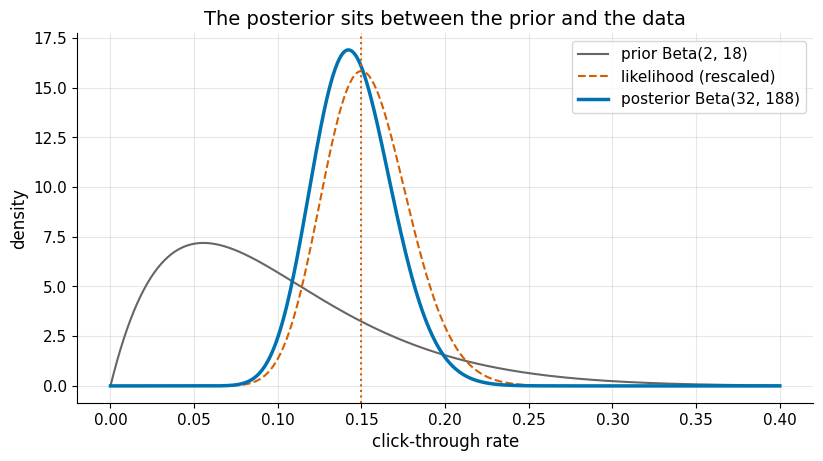

prior mean 0.1 | MLE 0.15 | posterior mean 0.1455


In [2]:
a0, b0, x1, n1 = 2, 18, 30, 200; th = np.linspace(0, 0.4, 600); prior = stats.beta.pdf(th, a0, b0); like = stats.binom.pmf(x1, n1, th); like_n = like / np.trapezoid(like, th); post = stats.beta.pdf(th, a0 + x1, b0 + n1 - x1)
fig, ax = plt.subplots(figsize=(9.5, 4.8)); ax.plot(th, prior, color=NEUTRAL, label="prior Beta(2, 18)"); ax.plot(th, like_n, color=HIGHLIGHT, linestyle="--", label="likelihood (rescaled)"); ax.plot(th, post, color=MAIN, linewidth=2.5, label="posterior Beta(32, 188)")
ax.axvline(x1 / n1, color=HIGHLIGHT, linestyle=":"); ax.set_xlabel("click-through rate"); ax.set_ylabel("density"); ax.set_title("The posterior sits between the prior and the data"); ax.legend()
plt.show()
print("prior mean", a0 / (a0 + b0), "| MLE", x1 / n1, "| posterior mean", round((a0 + x1) / (a0 + b0 + n1), 4))
assert abs((a0 + x1) / (a0 + b0 + n1) - 32 / 220) < 1e-12

### 7.2 Sequential updating
The posterior after 0, 10, 50, 200 and 1,000 impressions of an ad whose true click rate is 15 %: the curves narrow and move towards 0.15, and the prior is forgotten.

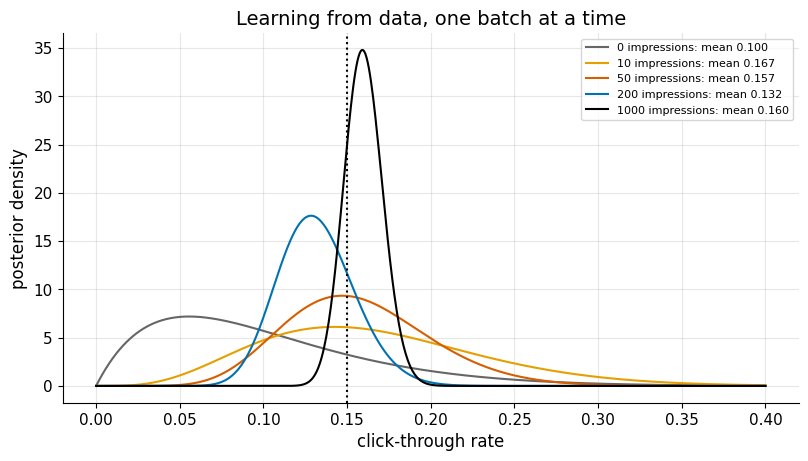

In [3]:
g = np.random.default_rng(5); clicks = g.random(1000) < 0.15; fig, ax = plt.subplots(figsize=(9.5, 4.8))
for m, colr in zip([0, 10, 50, 200, 1000], [NEUTRAL, SIM, HIGHLIGHT, MAIN, "black"]):
    s_ = clicks[:m].sum(); ax.plot(th, stats.beta.pdf(th, a0 + s_, b0 + m - s_), color=colr, label=f"{m} impressions: mean {(a0 + s_) / (a0 + b0 + m):.3f}")
ax.axvline(0.15, color="black", linestyle=":"); ax.set_xlabel("click-through rate"); ax.set_ylabel("posterior density"); ax.set_title("Learning from data, one batch at a time"); ax.legend(fontsize=8)
plt.show()
# sequential equals batch
sa, sb = a0, b0
for c in clicks[:200]: sa += c; sb += 1 - c
assert (sa, sb) == (a0 + clicks[:200].sum(), b0 + 200 - clicks[:200].sum())

### 7.3 Who has more influence: prior or data?
The weight on the data, $n/(a+b+n)$, for three prior strengths: the weight of the prior fades like $1/n$.

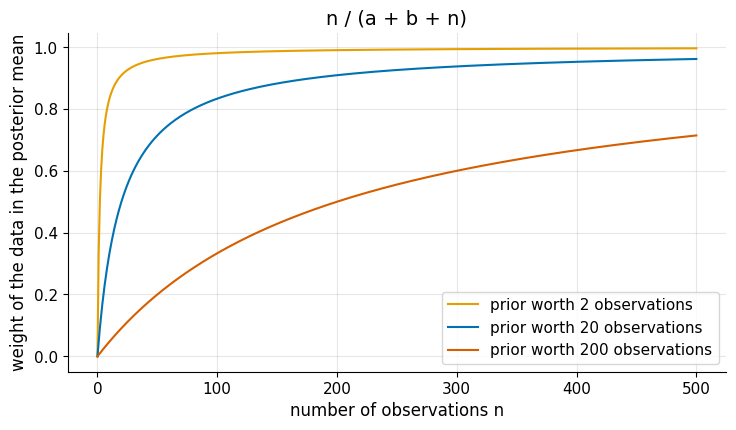

In [4]:
ns = np.arange(0, 501); fig, ax = plt.subplots(figsize=(8.5, 4.4))
for pr, colr in [(2, SIM), (20, MAIN), (200, HIGHLIGHT)]: ax.plot(ns, ns / (pr + ns), color=colr, label=f"prior worth {pr} observations")
ax.set_xlabel("number of observations n"); ax.set_ylabel("weight of the data in the posterior mean"); ax.legend(); ax.set_title("n / (a + b + n)")
plt.show()

## 8. 3D visuals

### 8.1 Static: the posterior surface as data accumulate
Posterior density of a click rate over $(\theta,n)$ when the data are exactly 15 % successes: the ridge sharpens and the mass concentrates at 0.15 as $n$ grows. This is "learning" drawn as a surface.

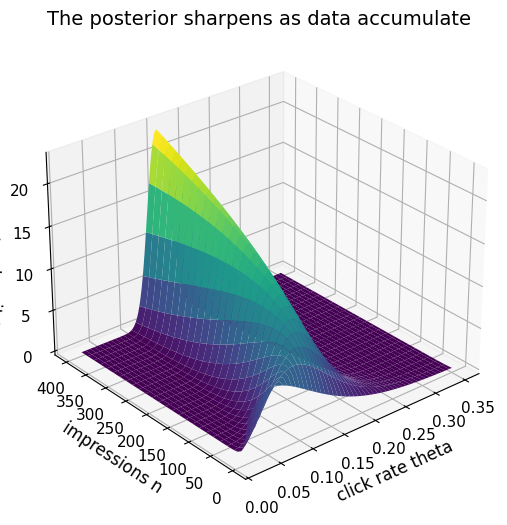

In [5]:
tg = np.linspace(0.02, 0.35, 150); ng = np.arange(0, 401, 8); Tg, Ng = np.meshgrid(tg, ng); Z = stats.beta.pdf(Tg, a0 + 0.15 * Ng, b0 + 0.85 * Ng)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Tg, Ng, Z, cmap="viridis", edgecolor="none"); ax.set_xlabel("click rate theta"); ax.set_ylabel("impressions n"); ax.set_zlabel("posterior density"); ax.set_title("The posterior sharpens as data accumulate"); ax.view_init(elev=28, azim=-130)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Rotate and hover.

In [6]:
fig = go.Figure(go.Surface(x=tg, y=ng, z=Z, colorscale="Viridis")); fig.update_layout(title="Posterior density over (theta, n)", width=760, height=560, scene=dict(xaxis_title="theta", yaxis_title="n", zaxis_title="density")); fig.show()

### 8.3 Static: posterior mean over (prior strength, sample size)
For observed rate 15 % and prior mean 10 %, the posterior mean as the prior strength $a+b$ and the sample size $n$ vary.

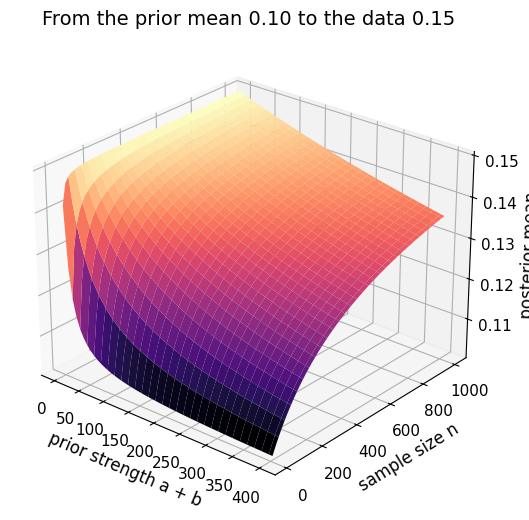

In [7]:
st = np.linspace(2, 400, 60); nn = np.linspace(10, 1000, 60); Sg, Ng2 = np.meshgrid(st, nn); PM = (0.10 * Sg + 0.15 * Ng2) / (Sg + Ng2)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Sg, Ng2, PM, cmap="magma", edgecolor="none"); ax.set_xlabel("prior strength a + b"); ax.set_ylabel("sample size n"); ax.set_zlabel("posterior mean"); ax.set_title("From the prior mean 0.10 to the data 0.15"); ax.view_init(elev=26, azim=-50)
plt.show()

## 9. Simulation vs theory

### 9.1 Bayes' rule by rejection
Draw $\theta$ from the prior Beta(2, 18), simulate 200 impressions, and **keep only the draws that produced exactly 30 clicks**. The kept $\theta$ values are samples from the posterior Beta(32, 188).

kept 47596 of 3000000 draws (acceptance 0.0159; theory P(x = 30) = 0.0159)
mean of kept draws 0.1455 vs 32/220 = 0.1455 | SD 0.0238 vs 0.0237 | KS p-value vs Beta(32, 188): 0.604


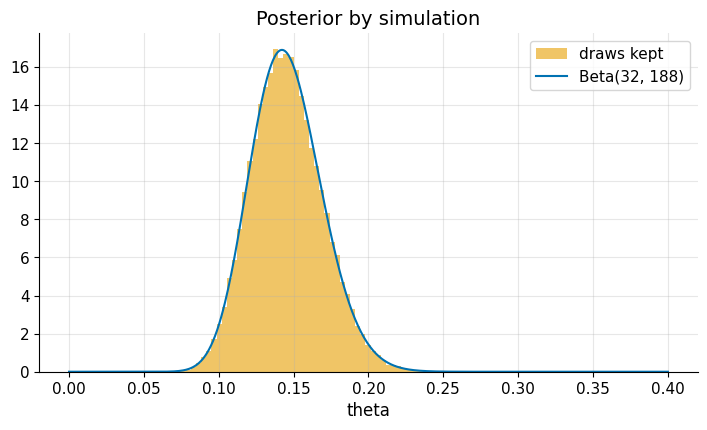

In [8]:
g = np.random.default_rng(1); M = 3_000_000; thp = g.beta(a0, b0, M); xs_ = g.binomial(n1, thp); kept = thp[xs_ == 30]
print(f"kept {kept.size} of {M} draws (acceptance {kept.size / M:.4f}; theory P(x = 30) = {stats.betabinom.pmf(30, 200, 2, 18):.4f})")
print(f"mean of kept draws {kept.mean():.4f} vs 32/220 = {32 / 220:.4f} | SD {kept.std():.4f} vs {stats.beta.std(32, 188):.4f} | KS p-value vs Beta(32, 188): {stats.kstest(kept, stats.beta(32, 188).cdf).pvalue:.3f}")
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.hist(kept, bins=60, density=True, color=SIM, alpha=0.6, label="draws kept"); ax.plot(th, post, color=MAIN, label="Beta(32, 188)"); ax.set_xlabel("theta"); ax.legend(); ax.set_title("Posterior by simulation")
plt.show()
assert abs(kept.mean() - 32 / 220) < 0.001 and abs(kept.size / M - stats.betabinom.pmf(30, 200, 2, 18)) < 0.001 and stats.kstest(kept, stats.beta(32, 188).cdf).pvalue > 0.01

### 9.2 Calibration of credible intervals
When the true $\theta$ is drawn from the prior itself, the 95 % credible interval contains it in exactly 95 % of experiments (Bayesian coverage).

In [9]:
g = np.random.default_rng(2); R = 100_000; tt = g.beta(a0, b0, R); xx = g.binomial(n1, tt); lo = stats.beta.ppf(0.025, a0 + xx, b0 + n1 - xx); hi = stats.beta.ppf(0.975, a0 + xx, b0 + n1 - xx); cover = np.mean((lo <= tt) & (tt <= hi))
print(f"coverage over the prior: {cover:.4f}"); assert abs(cover - 0.95) < 0.004

coverage over the prior: 0.9500


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
post_b = stats.beta(32, 188)
print("posterior object: stats.beta(a + x, b + n - x) | mean", round(post_b.mean(), 4), "| median", round(post_b.median(), 4), "| mode", round(31 / 218, 4))
print("credible interval: post.interval(0.95) ->", np.round(post_b.interval(0.95), 4), "| P(theta > 0.12): post.sf(0.12) ->", round(post_b.sf(0.12), 4))
print("evidence p(x): stats.betabinom.pmf(x, n, a, b) ->", round(stats.betabinom.pmf(30, 200, 2, 18), 5))
print("Gamma posterior: stats.gamma(a=alpha_n, scale=1 / beta_n) | Normal posterior: stats.norm(mu_n, np.sqrt(tau_n2))")
print("sampling: post.rvs(100000, random_state=rng)")

posterior object: stats.beta(a + x, b + n - x) | mean 0.1455 | median 0.1444 | mode 0.1422
credible interval: post.interval(0.95) -> [0.1021 0.1949] | P(theta > 0.12): post.sf(0.12) -> 0.8604
evidence p(x): stats.betabinom.pmf(x, n, a, b) -> 0.01591
Gamma posterior: stats.gamma(a=alpha_n, scale=1 / beta_n) | Normal posterior: stats.norm(mu_n, np.sqrt(tau_n2))
sampling: post.rvs(100000, random_state=rng)


## 11. Real-world worked examples

---
### Example 1 (main): click-through rate of a new ad (Beta-Binomial)

**Scenario.** Past ads in this category had a click-through rate (CTR) near 10 %. We encode this as a **Beta(2, 18)** prior (mean 0.10, worth 20 impressions). The new ad gets **30 clicks in 200 impressions**.

**Questions**
1. What is the posterior distribution, its mean, mode and 95 % credible interval?
2. What is the probability that the true CTR exceeds 12 %?
3. How does the answer change with a flat Beta(1, 1) prior and with a strong Beta(40, 360) prior?
4. How many impressions does the data need to carry 90 % of the weight against the Beta(2, 18) prior?

### 11.1 By hand
**Q1.** Posterior Beta$(2+30,\,18+170)=$ Beta(32, 188): mean $32/220=0.1455$, mode $(32-1)/(220-2)=0.1422$, SD $\sqrt{\frac{32\times188}{220^2\times221}}=0.0237$. A Normal approximation gives the 95 % interval $0.1455\pm1.96(0.0237)=(0.099,\,0.192)$; the exact Beta quantiles (computed below) are slightly skewed to the right: $(0.102,\,0.195)$.

**Q2.** $P(\theta>0.12)=1-\Phi\big(\frac{0.12-0.1455}{0.0237}\big)=\Phi(1.08)\approx0.86$ by the Normal approximation.

**Q3.** Flat prior: Beta(31, 171), mean $31/202=0.1535$. Strong prior Beta(40, 360) (mean 0.10, worth 400 impressions): Beta(70, 530), mean $70/600=0.1167$.

**Q4.** Weight on the data $=n/(20+n)=0.9$ gives $n=180$ impressions.

In [11]:
p1 = stats.beta(a0 + x1, b0 + n1 - x1); ci1 = p1.interval(0.95); pg = p1.sf(0.12); flat = stats.beta(1 + x1, 1 + n1 - x1); strong = stats.beta(40 + x1, 360 + n1 - x1)
print(f"Q1: posterior mean {p1.mean():.4f}, mode {(a0 + x1 - 1) / (a0 + b0 + n1 - 2):.4f}, SD {p1.std():.4f}, 95% interval ({ci1[0]:.4f}, {ci1[1]:.4f}), MLE {x1 / n1:.3f}")
print(f"Q2: P(CTR > 0.12) = {pg:.4f}")
print(f"Q3: flat prior mean {flat.mean():.4f}, 95% {np.round(flat.interval(0.95), 4)}, P(>0.12) {flat.sf(0.12):.3f} | strong prior mean {strong.mean():.4f}, 95% {np.round(strong.interval(0.95), 4)}, P(>0.12) {strong.sf(0.12):.3f}")
print("Q4: n = 9 * (a0 + b0) =", 9 * (a0 + b0))

Q1: posterior mean 0.1455, mode 0.1422, SD 0.0237, 95% interval (0.1021, 0.1949), MLE 0.150
Q2: P(CTR > 0.12) = 0.8604
Q3: flat prior mean 0.1535, 95% [0.1073 0.2062], P(>0.12) 0.914 | strong prior mean 0.1167, 95% [0.0922 0.1435], P(>0.12) 0.388
Q4: n = 9 * (a0 + b0) = 180


### 11.2 In code with `scipy`, and the asserts

In [12]:
assert abs(p1.mean() - 0.14545) < 1e-4 and abs(p1.std() - 0.023716) < 1e-4 and abs(ci1[0] - 0.10214) < 1e-3 and abs(ci1[1] - 0.19487) < 1e-3
assert abs(pg - 0.8604) < 0.002 and abs(flat.mean() - 31 / 202) < 1e-12 and abs(strong.mean() - 70 / 600) < 1e-12 and 9 * (a0 + b0) == 180
assert flat.mean() > p1.mean() > strong.mean() > 0.10                                  # more prior weight pulls the answer towards 0.10
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Two checks with the rejection sampler of 9.1: the posterior probability $P(\theta>0.12)$ and the interval computed from the kept draws.

In [13]:
print(f"simulated P(theta > 0.12) = {np.mean(kept > 0.12):.4f} (exact {pg:.4f}) | simulated 95% interval ({np.quantile(kept, 0.025):.4f}, {np.quantile(kept, 0.975):.4f})")
assert abs(np.mean(kept > 0.12) - pg) < 0.01 and abs(np.quantile(kept, 0.025) - ci1[0]) < 0.003 and abs(np.quantile(kept, 0.975) - ci1[1]) < 0.003

simulated P(theta > 0.12) = 0.8598 (exact 0.8604) | simulated 95% interval (0.1024, 0.1950)


### 11.4 Plots with the regions shaded

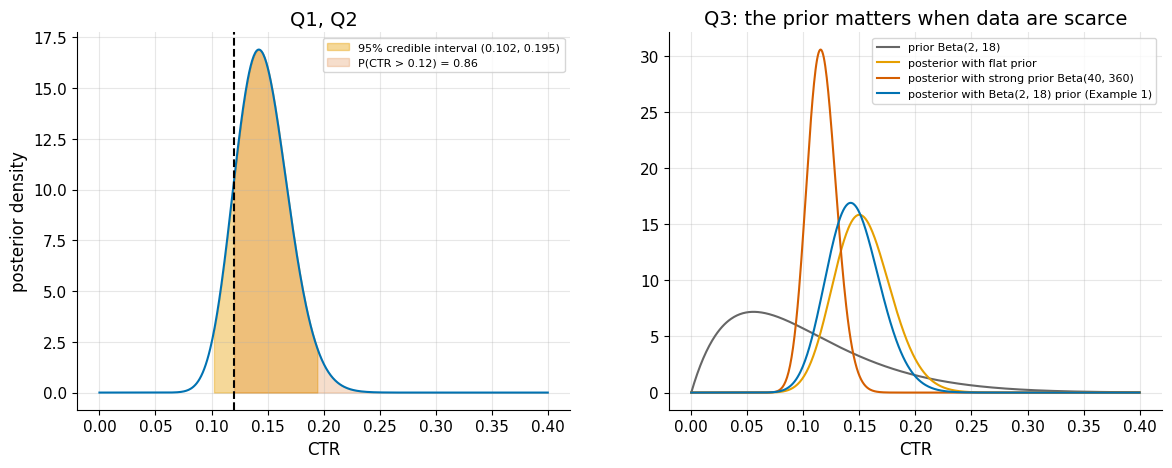

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
axes[0].plot(th, post, color=MAIN); axes[0].fill_between(th, post, where=(th >= ci1[0]) & (th <= ci1[1]), color=SIM, alpha=0.4, label=f"95% credible interval ({ci1[0]:.3f}, {ci1[1]:.3f})"); axes[0].axvline(0.12, color="black", linestyle="--"); axes[0].fill_between(th, post, where=th > 0.12, color=HIGHLIGHT, alpha=0.2, label=f"P(CTR > 0.12) = {pg:.2f}"); axes[0].set_xlabel("CTR"); axes[0].set_ylabel("posterior density"); axes[0].set_title("Q1, Q2"); axes[0].legend(fontsize=8)
for dist, nm, colr in [(stats.beta(a0, b0), "prior Beta(2, 18)", NEUTRAL), (flat, "flat prior", SIM), (strong, "strong prior Beta(40, 360)", HIGHLIGHT), (p1, "Beta(2, 18) prior (Example 1)", MAIN)]: axes[1].plot(th, dist.pdf(th), color=colr, label=("posterior with " if colr != NEUTRAL else "") + nm)
axes[1].set_xlabel("CTR"); axes[1].set_title("Q3: the prior matters when data are scarce"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The posterior is **Beta(32, 188)**: mean **0.1455**, mode 0.1422, SD 0.0237, 95 % credible interval **(0.102, 0.195)**. The observed rate was 15 %; the prior (mean 10 %, worth 20 impressions) pulls the estimate down by half a point. The rejection sampler of section 9 reproduces the posterior (47,596 kept draws, mean 0.1455, SD 0.0238), and the credible interval is calibrated: 95.0 % coverage over the prior.
- The probability that the true CTR exceeds 12 % is **0.860** (the simulation gives 0.8598).
- The prior matters when data are few: a flat prior gives mean 0.1535 and $P(\text{CTR}>0.12)=0.91$, the strong Beta(40, 360) prior gives mean 0.1167 and $P=0.39$. The data would need **180 impressions** to carry 90 % of the weight against the Beta(2, 18) prior.
- **Decision.** Report "CTR about 14.5 %, 95 % interval 10 % to 19.5 %, 86 % chance above 12 %" together with the prior used; if the decision flips under a reasonable alternative prior (the strong one), collect more impressions before deciding.

---
### Example 2: errors per hour on a server (Gamma-Poisson)

**Scenario.** The service of lesson 06_10 logged **47 errors in 30 hours**. Our prior from similar services is Gamma($\alpha=4$, $\beta=2$): mean 2 errors per hour, worth 2 hours of observation.

**Questions**
1. What is the posterior of the error rate $\lambda$, its mean and 95 % credible interval?
2. What is $P(\lambda>1)$ (is the service worse than one error per hour)?
3. Compare with the maximum likelihood estimate and the likelihood-ratio interval of 06_10.

### 11.6 By hand
**Q1.** Posterior Gamma$(4+47,\ 2+30)=$ Gamma(51, 32): mean $51/32=1.594$, SD $\sqrt{51}/32=0.223$; 95 % interval about $1.594\pm1.96(0.223)=(1.16,\,2.03)$ (the exact Gamma quantiles are computed below). **Q2.** $P(\lambda>1)=1-\Phi\big(\frac{1-1.594}{0.223}\big)=\Phi(2.66)\approx0.996$. **Q3.** The MLE is $47/30=1.567$; the posterior mean 1.594 lies between the MLE and the prior mean 2, pulled slightly up by the prior (weight $2/32=6\,\%$).

Q1: posterior Gamma(51, 32): mean 1.5938, SD 0.2232, 95% interval (1.1867, 2.0600) | Q2: P(rate > 1) = 0.99882 | Q3: MLE 1.5667; 06_10 LR interval (1.16, 2.06), exact Poisson interval (1.15, 2.08)
rejection check: kept 28713, mean 1.5958, P(rate > 1) 0.9989


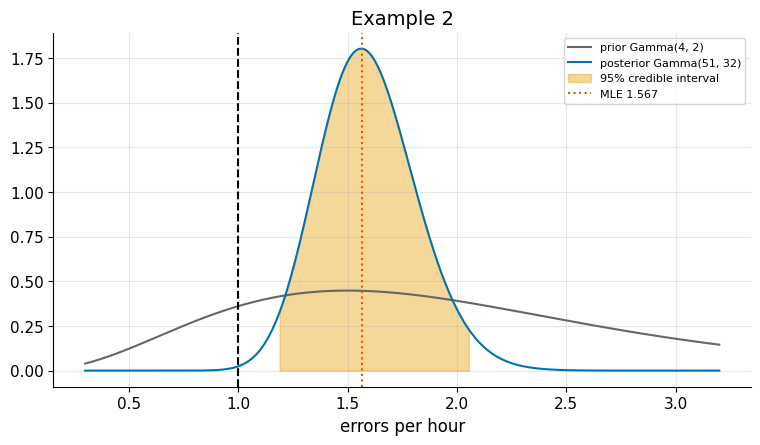

In [15]:
al0, be0, xe, Te = 4, 2, 47, 30; pe = stats.gamma(a=al0 + xe, scale=1 / (be0 + Te)); ci2 = pe.interval(0.95); p_gt1 = pe.sf(1.0)
print(f"Q1: posterior Gamma({al0 + xe}, {be0 + Te}): mean {pe.mean():.4f}, SD {pe.std():.4f}, 95% interval ({ci2[0]:.4f}, {ci2[1]:.4f}) | Q2: P(rate > 1) = {p_gt1:.5f} | Q3: MLE {xe / Te:.4f}; 06_10 LR interval (1.16, 2.06), exact Poisson interval (1.15, 2.08)")
g = np.random.default_rng(7); lam_s = g.gamma(al0, 1 / be0, 2_000_000); x_s = g.poisson(lam_s * Te); kept2 = lam_s[x_s == xe]; print(f"rejection check: kept {kept2.size}, mean {kept2.mean():.4f}, P(rate > 1) {np.mean(kept2 > 1):.4f}")
assert abs(pe.mean() - 51 / 32) < 1e-12 and abs(ci2[0] - 1.1867) < 0.002 and abs(ci2[1] - 2.0600) < 0.002 and abs(p_gt1 - 0.99882) < 5e-4 and abs(kept2.mean() - pe.mean()) < 0.01
fig, ax = plt.subplots(figsize=(9, 4.6)); lg = np.linspace(0.3, 3.2, 500); ax.plot(lg, stats.gamma.pdf(lg, al0, scale=1 / be0), color=NEUTRAL, label="prior Gamma(4, 2)"); ax.plot(lg, pe.pdf(lg), color=MAIN, label="posterior Gamma(51, 32)"); ax.fill_between(lg, pe.pdf(lg), where=(lg >= ci2[0]) & (lg <= ci2[1]), color=SIM, alpha=0.4, label="95% credible interval"); ax.axvline(1, color="black", linestyle="--"); ax.axvline(xe / Te, color=HIGHLIGHT, linestyle=":", label="MLE 1.567"); ax.set_xlabel("errors per hour"); ax.legend(fontsize=8); ax.set_title("Example 2")
plt.show()

### 11.7 Interpretation and decision (Example 2)
- The posterior for the error rate is **Gamma(51, 32)**: mean **1.594 errors per hour**, SD 0.223, 95 % credible interval **(1.19, 2.06)**; the probability that the service exceeds one error per hour is **0.9988**. A rejection simulation agrees (mean 1.596, $P=0.9989$).
- This is close to the frequentist answers of 06_10 (MLE 1.567; likelihood-ratio interval (1.16, 2.06); exact Poisson interval (1.15, 2.08)), because 30 hours of data outweigh a prior worth 2 hours; the prior mean 2 pulls the posterior mean up by 0.03.
- **Decision.** The service is almost certainly above the target of one error per hour, with a plausible range of 1.2 to 2.1 per hour; the Bayesian statement "99.9 % probability that the rate exceeds 1" answers the question the team asked directly.

---
### Example 3: calibrating a sensor (Normal-Normal)

**Scenario.** A temperature sensor has measurement noise SD $\sigma=1.5$ degrees. Before measuring, the room is believed to be $N(20,\,2^2)$. Five readings average **22.3** degrees.

**Questions**
1. What is the posterior of the true temperature?
2. How many readings would make the posterior SD smaller than 0.3 degrees?
3. Show that the posterior mean is the precision-weighted average of the prior mean and the sample mean.

### 11.8 By hand
**Q1.** Prior precision $1/4=0.25$; data precision $5/1.5^2=2.222$; posterior precision $2.472$, variance $0.4045$, SD $0.636$. Mean $=(0.25\times20+2.222\times22.3)/2.472=22.07$. **Q2.** Need $0.25+n/2.25\ge1/0.09=11.11$, i.e. $n\ge24.4$, so **25 readings**. **Q3.** Weights $0.25/2.472=0.101$ on the prior mean and $0.899$ on the sample mean: $0.101\times20+0.899\times22.3=22.07$.

Q1: posterior N(22.0674, 0.6360^2), 95% interval (20.821, 23.314) | Q2: n = 25 | Q3: weight on the prior mean 0.1011, on the data 0.8989
rejection check: kept 4130, mean 22.077, SD 0.647


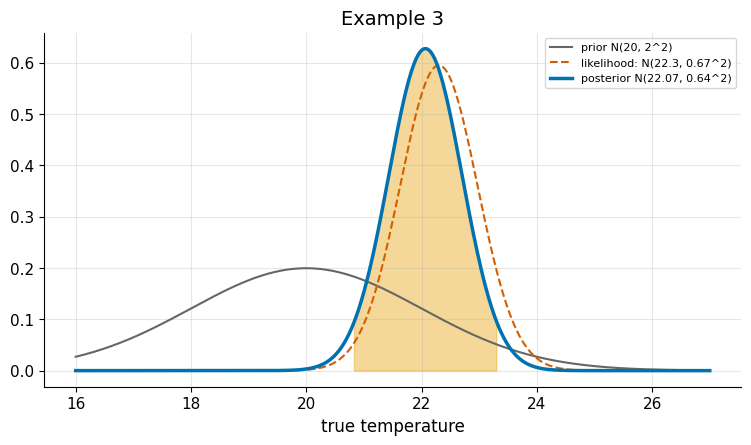

In [16]:
mu0, tau0, sg, nr, xbar = 20.0, 2.0, 1.5, 5, 22.3; prec = 1 / tau0 ** 2 + nr / sg ** 2; mun = (mu0 / tau0 ** 2 + nr * xbar / sg ** 2) / prec; taun = np.sqrt(1 / prec); wp = (1 / tau0 ** 2) / prec
n_need = int(np.ceil((1 / 0.3 ** 2 - 1 / tau0 ** 2) * sg ** 2)); print(f"Q1: posterior N({mun:.4f}, {taun:.4f}^2), 95% interval ({mun - 1.96 * taun:.3f}, {mun + 1.96 * taun:.3f}) | Q2: n = {n_need} | Q3: weight on the prior mean {wp:.4f}, on the data {1 - wp:.4f}")
g = np.random.default_rng(3); mu_s = g.normal(mu0, tau0, 2_000_000); xb_s = g.normal(mu_s, sg / np.sqrt(nr)); k3 = mu_s[np.abs(xb_s - xbar) < 0.01]; print(f"rejection check: kept {k3.size}, mean {k3.mean():.3f}, SD {k3.std():.3f}")
assert abs(mun - 22.0674) < 1e-3 and abs(taun - 0.6360) < 1e-3 and n_need == 25 and abs(k3.mean() - mun) < 0.03 and abs(k3.std() - taun) < 0.02
fig, ax = plt.subplots(figsize=(9, 4.6)); tg3 = np.linspace(16, 27, 500); ax.plot(tg3, stats.norm.pdf(tg3, mu0, tau0), color=NEUTRAL, label="prior N(20, 2^2)"); ax.plot(tg3, stats.norm.pdf(tg3, xbar, sg / np.sqrt(nr)), color=HIGHLIGHT, linestyle="--", label="likelihood: N(22.3, 0.67^2)"); ax.plot(tg3, stats.norm.pdf(tg3, mun, taun), color=MAIN, linewidth=2.5, label=f"posterior N({mun:.2f}, {taun:.2f}^2)"); ax.fill_between(tg3, stats.norm.pdf(tg3, mun, taun), where=(tg3 >= mun - 1.96 * taun) & (tg3 <= mun + 1.96 * taun), color=SIM, alpha=0.4); ax.set_xlabel("true temperature"); ax.legend(fontsize=8); ax.set_title("Example 3")
plt.show()

### 11.9 Interpretation and decision (Example 3)
- The posterior is **N(22.07, 0.636²)**, 95 % credible interval **(20.82, 23.31)**. The sample mean is 22.3 and the prior mean 20; the five readings carry 90 % of the weight (0.899) because their precision (2.22) is nine times the prior's (0.25). The rejection check agrees (mean 22.08, SD 0.65).
- To bring the posterior SD below 0.3 degrees we need **25 readings**; the prior is worth only about half a reading.
- **Decision.** Report the room at 22.1 degrees with an uncertainty of 0.6; take 25 readings if a precision of 0.3 degrees is needed. This is exactly the update step of a Kalman filter.

## 12. Where it is used

### Statistics
- **Bayesian estimation and testing** with prior knowledge: rare-event rates, small clinical trials, hierarchical models (partial pooling across groups), empirical Bayes (shrinking noisy estimates towards the group mean).
- **Reliability and quality control** with Gamma-Poisson updates of failure rates.

### Data science
- **Click-through and conversion rates:** a Beta prior stabilises estimates for new items with few impressions (ranking the "best" items with a small sample would otherwise be dominated by noise).
- **A/B testing** with a posterior probability of "B is better" (07_02) and **Thompson sampling** (07_04).

### ML and AI
- **Regularisation** is a prior: ridge = Gaussian prior, lasso = Laplace prior; MAP estimation; weight decay.
- **Bayesian neural networks, Gaussian processes, Kalman filters** (Normal-Normal updating in time), naive Bayes, topic models (Dirichlet prior), and the Bayesian view of in-context learning and of model uncertainty.

## 13. Common pitfalls and misconceptions

- **"The prior is arbitrary."** It is an explicit assumption, which can be checked by changing it (Example 1 Q3); with enough data it washes out. Hidden assumptions of non-Bayesian methods are not more objective, only less visible.
- **Reading a credible interval as a confidence interval.** A 95 % credible interval says "given the prior and data, $\theta$ lies in it with probability 95 %"; a confidence interval makes a statement about the procedure (06_02).
- **Over-confident priors** (Beta(400, 3600)) can ignore the data for a long time; always report a sensitivity analysis.
- **Flat is not "no information":** a uniform prior on $\theta$ is not uniform on $\theta^2$ or on the log-odds; the choice of parametrisation matters.
- **Forgetting the evidence $p(x)$** when comparing models: the posterior of each model is only defined up to it.
- **Conjugacy is convenient, not necessary:** when the posterior has no closed form use MCMC (07_03).

## 14. Exercises

1. A coin is thrown 10 times and lands heads 7 times. With a uniform prior, give the posterior, its mean and the probability that the coin is biased towards heads ($\theta>0.5$).
2. With a Beta(5, 5) prior and 7 heads in 10, compare the posterior mean with the MLE; how many throws would be needed for the posterior mean to be within 0.01 of the MLE if the data stay at 70 %?
3. Customers arrive at a shop; 12 arrivals in 4 hours. With a Gamma(2, 1) prior on the rate per hour, give the posterior mean and the probability that the rate exceeds 2.
4. A prior $N(100, 15^2)$ for an IQ-like score and one measurement with noise SD 10 equal to 120: give the posterior mean and SD.
5. Show by sequential updating that three batches (3 successes of 10, 5 of 10, 2 of 10) from a Beta(1, 1) prior give the same posterior as one batch of 10 of 30.
6. (Harder) Simulate by rejection the posterior for $\theta$ after 3 successes in 5 trials with a Beta(2, 2) prior and compare with the exact Beta(5, 4).

Solutions are at the end.

## 15. Summary table

| Likelihood | Prior | Posterior | Mean |
|---|---|---|---|
| Binomial($n$, $\theta$) | Beta($a$, $b$) | Beta($a+x$, $b+n-x$) | $\frac{a+x}{a+b+n}$ |
| Poisson($\lambda T$) | Gamma($\alpha$, $\beta$) | Gamma($\alpha+x$, $\beta+T$) | $\frac{\alpha+x}{\beta+T}$ |
| Normal, known $\sigma$ | Normal($\mu_0$, $\tau_0^2$) | Normal($\mu_n$, $\tau_n^2$) | precision-weighted mean |
| scipy | `beta`, `gamma`, `norm`, `betabinom`; `.interval`, `.sf` | | |

## Solutions

In [17]:
q1 = stats.beta(8, 4); print(f"1: Beta(8, 4), mean {q1.mean():.4f}, P(theta > 0.5) = {q1.sf(0.5):.4f}")
q2 = stats.beta(12, 8); w = 10 / (10 + 10); print(f"2: posterior mean {q2.mean():.3f} vs MLE 0.7; need |(5 + 0.7n)/(10 + n) - 0.7| = 2/(10 + n) <= 0.01 -> n >= {int(np.ceil(2 / 0.01 - 10))}")
q3 = stats.gamma(a=2 + 12, scale=1 / (1 + 4)); print(f"3: Gamma(14, 5), mean {q3.mean():.3f}, P(rate > 2) = {q3.sf(2):.4f}")
tp = 1 / 15 ** 2 + 1 / 10 ** 2; mp = (100 / 15 ** 2 + 120 / 10 ** 2) / tp; print(f"4: posterior mean {mp:.2f}, SD {np.sqrt(1 / tp):.2f}")
a_, b_ = 1, 1
for s_, n_ in [(3, 10), (5, 10), (2, 10)]: a_ += s_; b_ += n_ - s_
print(f"5: sequential Beta({a_}, {b_}) vs batch Beta({1 + 10}, {1 + 20})"); assert (a_, b_) == (11, 21)
g = np.random.default_rng(9); t6 = g.beta(2, 2, 2_000_000); k6 = t6[g.binomial(5, t6) == 3]; print(f"6: kept {k6.size}, mean {k6.mean():.4f} (exact 5/9 = {5 / 9:.4f}), KS p = {stats.kstest(k6, stats.beta(5, 4).cdf).pvalue:.3f}")
assert abs(k6.mean() - 5 / 9) < 0.003

1: Beta(8, 4), mean 0.6667, P(theta > 0.5) = 0.8867
2: posterior mean 0.600 vs MLE 0.7; need |(5 + 0.7n)/(10 + n) - 0.7| = 2/(10 + n) <= 0.01 -> n >= 190
3: Gamma(14, 5), mean 2.800, P(rate > 2) = 0.8645
4: posterior mean 113.85, SD 8.32
5: sequential Beta(11, 21) vs batch Beta(11, 21)


6: kept 428192, mean 0.5557 (exact 5/9 = 0.5556), KS p = 0.840


**1.** Posterior **Beta(8, 4)**, mean 0.667; $P(\theta>0.5)=$ **0.887**.

**2.** With Beta(5, 5) the posterior is Beta(12, 8) with mean **0.600** against the MLE 0.7. The gap is $2/(10+n)$, so we need $n\ge$ **190** throws (data kept at 70 %) for the gap to be below 0.01.

**3.** Posterior **Gamma(14, 5)**, mean **2.80** arrivals per hour, $P(\lambda>2)=$ **0.865**.

**4.** Posterior mean **113.85**, SD **8.32** (precision-weighted: the measurement with SD 10 gets weight 0.69).

**5.** Sequential updates Beta(1,1) $\to$ (4, 8) $\to$ (9, 13) $\to$ (11, 21) equal the single-batch posterior Beta(11, 21).

**6.** The rejection sampler keeps 428,192 draws with mean 0.5557 (exact 5/9 = 0.5556) and the Kolmogorov-Smirnov test against Beta(5, 4) gives p = 0.84.